# ✍️ Minha Caligrafia vs Rede Neural

Bem-vindo(a) ao exercício final! Agora você vai testar se a Rede Neural que treinamos consegue **reconhecer a sua própria letra**.

---

## 🎯 O que vamos fazer?

1. **Construir** sua própria Rede Neural do zero (igual à do Notebook 1)
2. **Treinar** com o dataset MNIST
3. **Fotografar** seus próprios números escritos à mão
4. **Testar** se a IA consegue reconhecer a sua caligrafia
5. **Comparar** seu resultado com o dos seus colegas!

---

## 📋 Antes de começar — Prepare o material:

1. Pegue uma folha **branca** e uma **caneta ou lápis**
2. Escreva os dígitos de **0 a 9**, bem grandes e centralizados
3. Fotografe cada número **separadamente** com um fundo branco
4. Salve as fotos com os nomes: `0.jpg`, `1.jpg`, ..., `9.jpg`

> 💡 **Dica de ouro:** O MNIST foi treinado com números **escuros sobre fundo claro**. Escreva com caneta preta em papel branco para melhores resultados!

---

### 📌 Como usar este notebook?
Execute cada célula clicando no botão **▶️** ao lado, ou pressione **`Shift + Enter`**.
Siga sempre de cima para baixo — cada etapa depende da anterior!

---
## 📦 ETAPA 1 — Importar as Bibliotecas

Assim como no Notebook 1, começamos importando tudo que precisamos.

> 💡 Se você já executou o Notebook 1 nesta mesma sessão do Colab, as bibliotecas já estão instaladas. Mesmo assim, execute esta célula para garantir!

In [ ]:
# Importa todas as bibliotecas necessárias
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import files
import os

print('✅ Bibliotecas importadas com sucesso!')
print(f'📌 TensorFlow versão: {tf.__version__}')

✅ Bibliotecas importadas com sucesso!
📌 TensorFlow versão: 2.20.0


---
## 🔢 ETAPA 2 — Carregar e Preparar o Dataset MNIST

Vamos carregar o MNIST novamente e preparar os dados, exatamente como fizemos no Notebook 1.

> 🔁 **Por que repetir isso?** Cada notebook no Colab roda em um ambiente separado. Precisamos recarregar os dados aqui!

In [ ]:
# Carrega o dataset MNIST
(x_treino, y_treino), (x_teste, y_teste) = tf.keras.datasets.mnist.load_data()

# Normaliza pixels para [0, 1]
x_treino = x_treino / 255.0
x_teste  = x_teste  / 255.0

# Adiciona dimensão do canal (28x28x1)
x_treino = x_treino.reshape(-1, 28, 28, 1)
x_teste  = x_teste.reshape(-1, 28, 28, 1)

print('✅ Dataset MNIST carregado e preparado!')
print(f'   Treino: {x_treino.shape[0]:,} imagens \
| Teste: {x_teste.shape[0]:,} imagens')

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Dataset MNIST carregado e preparado!
   Treino: 60,000 imagens | Teste: 10,000 imagens


---
## 🧠 ETAPA 3 — Construir SUA Rede Neural

Chegou a hora de você **construir sua própria rede neural!**

### 🎮 Sua missão:

Abaixo está a estrutura da rede do Notebook 1. Você pode:
- ✅ Usar exatamente como está
- 🔧 **Modificar** os números e comparar os resultados com seus colegas!

### O que você pode mudar?

| O que mudar | Onde | Efeito esperado |
|-------------|------|----------------|
| Número de filtros Conv2D | `32` ou `64` | Mais filtros = mais padrões detectados |
| Neurônios na Dense | `128` | Mais = mais capacidade, mas mais lento |
| Acrescentar `Dropout(0.5)` | Após Dense | Evita decorar — melhora generalização |

> ⚠️ **Não mude** o `input_shape=(28, 28, 1)` nem a última camada `Dense(10, 'softmax')` — esses são fixos pelo formato do MNIST!

In [ ]:
# ✏️ CONSTRUA SUA REDE AQUI!
# Você pode modificar os valores marcados com '← mude aqui'

minha_rede = models.Sequential([
    # Primeira camada convolucional
    # ← Experimente trocar 32 por 16 ou 64
    layers.Conv2D(32, (3, 3), activation='relu',
                  input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    # Segunda camada convolucional
    # ← Experimente trocar 64 por 32 ou 128
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    # Converte para vetor 1D
    layers.Flatten(),
    # Camada densa — o 'cérebro' da classificação
    # ← Experimente trocar 128 por 64 ou 256
    layers.Dense(128, activation='relu'),
    # ← Opcional: adicione Dropout para evitar overfitting
    # layers.Dropout(0.5),
    # Camada de saída — NÃO MUDE! 10 = dígitos de 0 a 9
    layers.Dense(10, activation='softmax')
])

# Compila a rede
minha_rede.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print('✅ Sua rede neural foi criada!')
minha_rede.summary()

✅ Sua rede neural foi criada!


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

---
## 🏋️ ETAPA 4 — Treinar SUA Rede

Agora vamos treinar a rede que você acabou de criar!

> ✏️ **Anote o número de épocas que você usou** — isso será importante na comparação com os colegas!

Dica: comece com **5 épocas**. Se quiser mais precisão, tente **10 épocas**.

In [ ]:
# ✏️ Mude o número de épocas aqui se quiser!
EPOCAS = 5  # ← experimente 5, 10 ou 15

print(f'🏋️ Treinando por {EPOCAS} épocas...\n')

historico = minha_rede.fit(
    x_treino, y_treino,
    epochs=EPOCAS,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print('\n✅ Treinamento concluído!')

🏋️ Treinando por 5 épocas...

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 54ms/step - accuracy: 0.9491 - loss: 0.1694 - val_accuracy: 0.9855 - val_loss: 0.0545
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 53ms/step - accuracy: 0.9842 - loss: 0.0508 - val_accuracy: 0.9880 - val_loss: 0.0497
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 52ms/step - accuracy: 0.9898 - loss: 0.0350 - val_accuracy: 0.9812 - val_loss: 0.0592
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - accuracy: 0.9911 - loss: 0.0276 - val_accuracy: 0.9900 - val_loss: 0.0350
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 54ms/step - accuracy: 0.9941 - loss: 0.0184 - val_accuracy: 0.9890 - val_loss: 0.0399

✅ Treinamento concluído!


---
## 📊 ETAPA 5 — Avaliar Sua Rede

Vamos ver a acurácia da **sua** rede nas 10.000 imagens de teste.

> 📝 **Anote sua acurácia!** Você vai comparar com a dos colegas no final.

   🏆 RESULTADO DA SUA REDE NO MNIST
   ✅ Acurácia no teste : 98.82%
   📉 Perda no teste   : 0.0334

📝 ANOTE PARA COMPARAR: 98.82%


/tmp/ipykernel_2534/4083903211.py:36: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


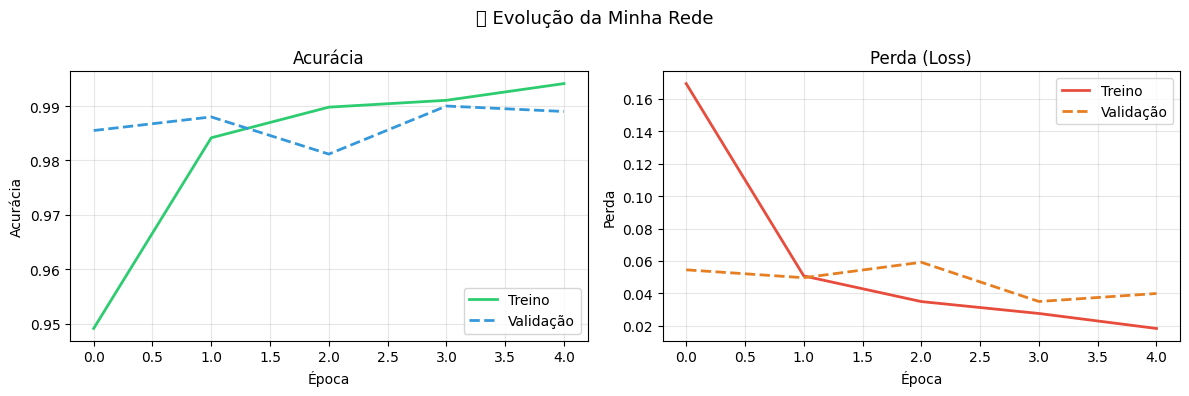

In [ ]:
# Avalia no conjunto de teste
perda, acuracia = minha_rede.evaluate(x_teste, y_teste, verbose=0)

print('=' * 50)
print('   🏆 RESULTADO DA SUA REDE NO MNIST')
print('=' * 50)
print(f'   ✅ Acurácia no teste : {acuracia * 100:.2f}%')
print(f'   📉 Perda no teste   : {perda:.4f}')
print('=' * 50)
print(f'\n📝 ANOTE PARA COMPARAR: {acuracia * 100:.2f}%')

# Plota gráfico de treinamento
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('📈 Evolução da Minha Rede', fontsize=13)

ax1.plot(historico.history['accuracy'],     label='Treino',
         color='#2ecc71', linewidth=2)
ax1.plot(historico.history['val_accuracy'], label='Validação',
         color='#3498db', linewidth=2, linestyle='--')
ax1.set_title('Acurácia')
ax1.set_xlabel('Época')
ax1.set_ylabel('Acurácia')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(historico.history['loss'],     label='Treino',
         color='#e74c3c', linewidth=2)
ax2.plot(historico.history['val_loss'], label='Validação',
         color='#e67e22', linewidth=2, linestyle='--')
ax2.set_title('Perda (Loss)')
ax2.set_xlabel('Época')
ax2.set_ylabel('Perda')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 📸 ETAPA 6 — Enviar Suas Fotos

Agora a parte mais divertida: vamos testar com a **sua própria caligrafia!**

### 📝 Como preparar suas fotos:

1. Escreva os dígitos **0, 1, 2, 3, 4, 5, 6, 7, 8, 9** em papel branco
2. Escreva cada número **bem grande** no centro da folha
3. Fotografe com **boa iluminação** (sem sombras)
4. Envie quantos dígitos quiser!

> ⚠️ O modelo foi treinado com **dígito escuro sobre fundo claro**. Se a sua foto tiver o contrário (branco sobre preto), o código irá inverter automaticamente!

In [ ]:
# Abre a janela para você enviar suas fotos
print('📂 Envie as fotos dos seus números escritos à mão...')
print('   (você pode enviar várias fotos de uma vez!)')
arquivos = files.upload()

nomes_arquivos = list(arquivos.keys())
print(f'\n✅ {len(nomes_arquivos)} imagem(ns) carregada(s):')
for nome in nomes_arquivos:
    print(f'   📄 {nome}')

📂 Envie as fotos dos seus números escritos à mão...
   (você pode enviar várias fotos de uma vez!)


Saving 8.jpg to 8.jpg
Saving 7.jpg to 7.jpg
Saving 4.jpg to 4.jpg
Saving 2.jpg to 2.jpg
Saving 1.jpg to 1.jpg

✅ 5 imagem(ns) carregada(s):
   📄 8.jpg
   📄 7.jpg
   📄 4.jpg
   📄 2.jpg
   📄 1.jpg


---
## 🔄 ETAPA 7 — Pré-processar Suas Imagens

As suas fotos são bem diferentes das imagens do MNIST. Precisamos transformá-las!

```
Sua foto colorida        →   Tons de cinza   →   28x28 px   →   Inverter cores   →   Normalizar
(ex: 3024×4032 pixels)       (1 canal)           (MNIST)        (fundo preto)        (÷ 255)
```

> 💡 **Por que inverter?** O MNIST tem dígitos **claros sobre fundo escuro** (pixels brancos = número). Sua foto provavelmente tem o contrário — precisamos inverter para o modelo entender!

In [ ]:
"""
Transforma uma foto do seu número no formato que o modelo espera.

Passos:
1. Abre a imagem e converte para tons de cinza
2. Redimensiona para 28x28 pixels (formato MNIST)
3. Inverte as cores se necessário (dígito = branco, fundo = preto)
4. Normaliza os pixels para [0, 1]
5. Adiciona dimensões para o modelo (batch e canal)
"""


def preparar_minha_imagem(caminho):

    # Abre e converte para tons de cinza
    img = Image.open(caminho).convert('L')
    # Redimensiona para 28x28 (tamanho do MNIST)
    img = img.resize((28, 28))
    # Converte para array NumPy
    arr = np.array(img)
    # Inverte as cores se o fundo for mais claro que o dígito
    # (no MNIST: fundo escuro = pixel baixo, dígito claro = pixel alto)
    if arr.mean() > 127:  # fundo claro → inverte
        arr = 255 - arr
    # Normaliza para [0, 1]
    arr = arr / 255.0
    # Adiciona dimensões: (1, 28, 28, 1) = (batch, altura, largura, canal)
    arr = arr.reshape(1, 28, 28, 1)

    return arr

print('✅ Função de pré-processamento criada!')
print('📌 Use: preparar_minha_imagem("nome_do_arquivo.jpg")')

✅ Função de pré-processamento criada!
📌 Use: preparar_minha_imagem("nome_do_arquivo.jpg")


---
## 🤖 ETAPA 8 — Testar Sua Caligrafia!

Agora o momento da verdade: vamos ver se a IA consegue ler a **sua letra**.

Para cada foto que você enviou, veremos:
- A imagem original
- A imagem processada (como a IA a vê)
- As probabilidades para cada dígito
- O resultado final da previsão

/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


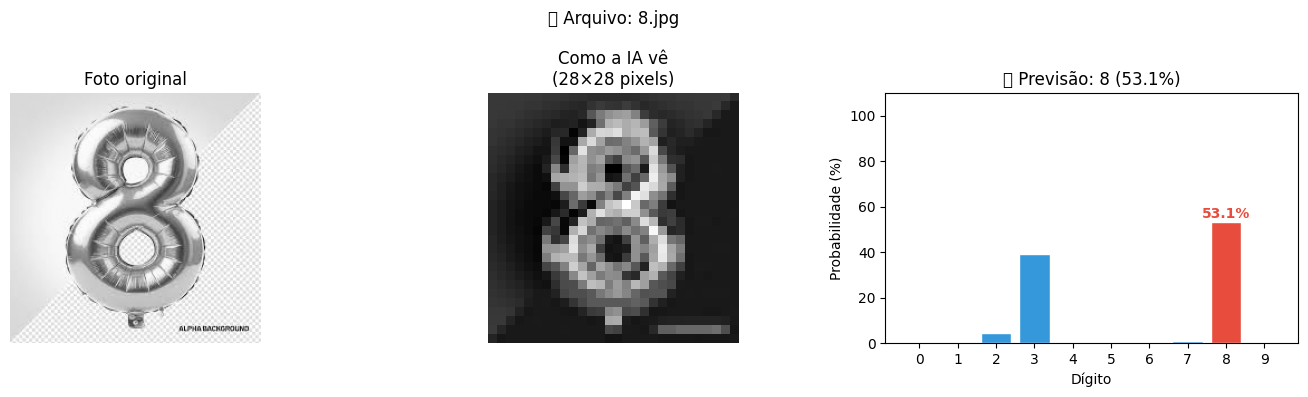

   🔮 Resultado: dígito 8 com 53.1%     de confiança



/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


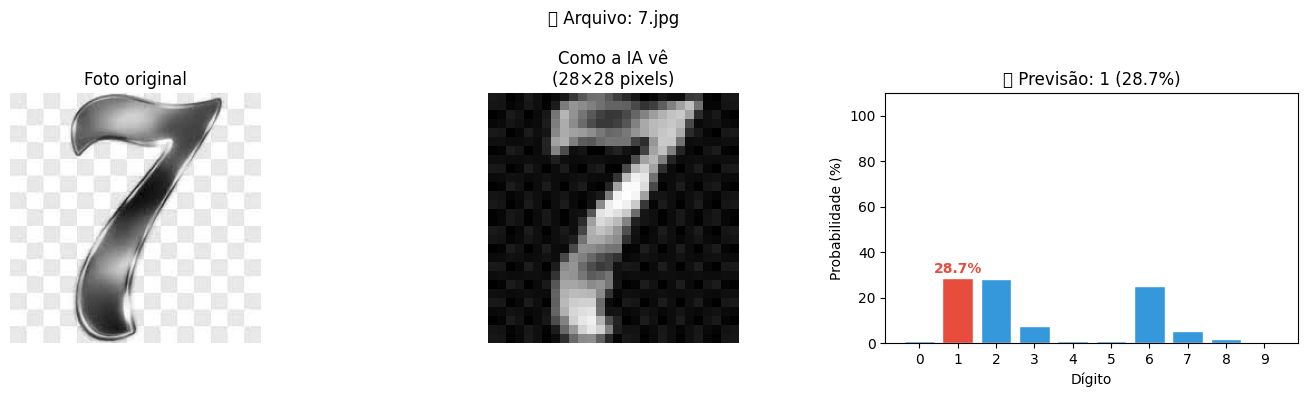

   🔮 Resultado: dígito 1 com 28.7%     de confiança



/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


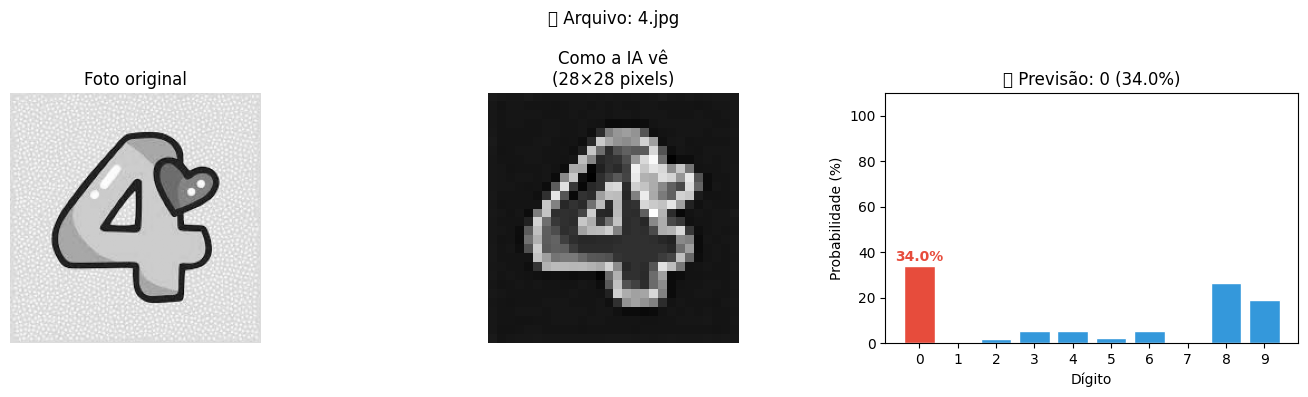

   🔮 Resultado: dígito 0 com 34.0%     de confiança



/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


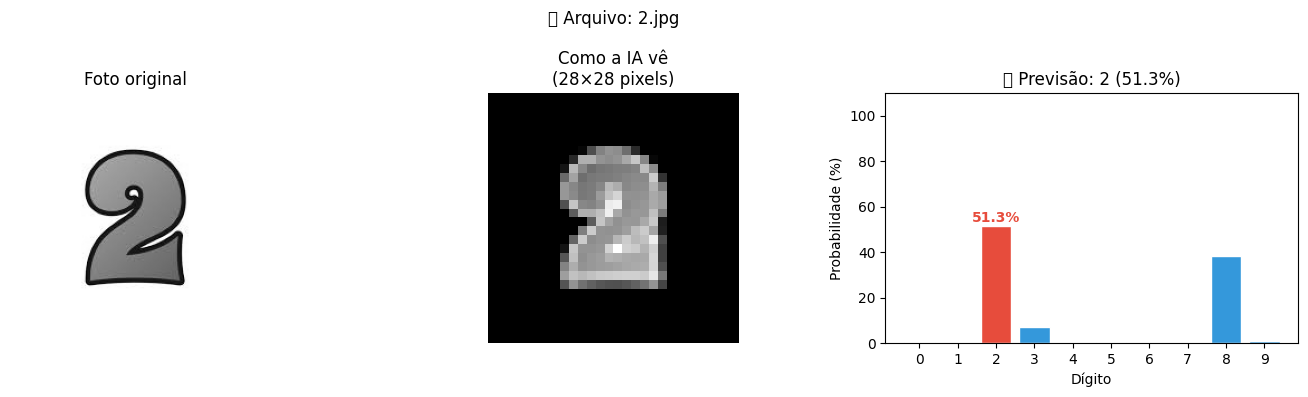

   🔮 Resultado: dígito 2 com 51.3%     de confiança



/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2534/3356533122.py:49: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


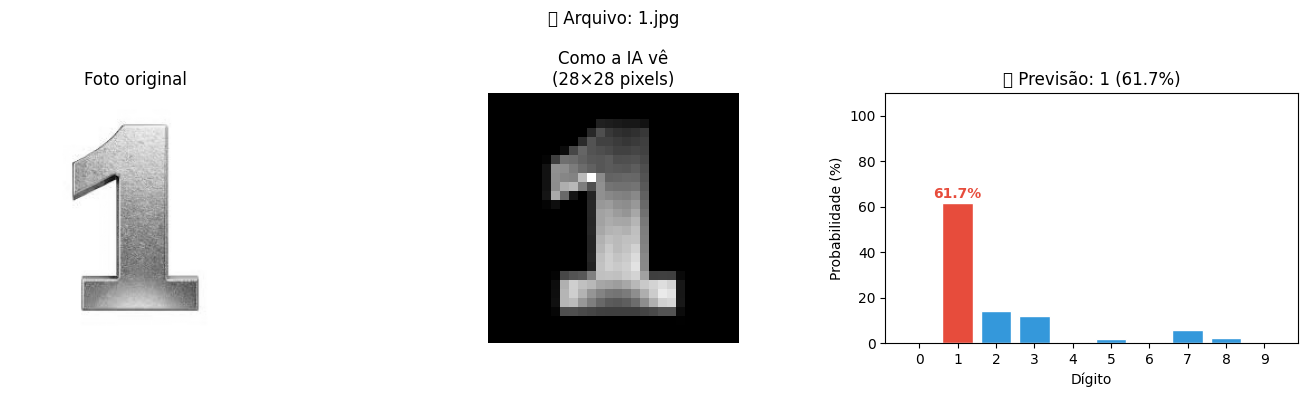

   🔮 Resultado: dígito 1 com 61.7%     de confiança



In [ ]:
# Testa cada imagem enviada
resultados_minha_caligrafia = []

for nome_arquivo in nomes_arquivos:
    # Prepara a imagem
    arr = preparar_minha_imagem(nome_arquivo)

    # Faz a previsão
    probs = minha_rede.predict(arr, verbose=0)[0]
    digito_previsto = np.argmax(probs)
    confianca = probs[digito_previsto] * 100

    resultados_minha_caligrafia.append({
        'arquivo': nome_arquivo,
        'previsto': digito_previsto,
        'confianca': confianca,
        'probs': probs
    })

    # --- Visualização ---
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
    fig.suptitle(f'📸 Arquivo: {nome_arquivo}', fontsize=12)

    # Imagem original
    img_original = Image.open(nome_arquivo).convert('L')
    ax1.imshow(img_original, cmap='gray')
    ax1.set_title('Foto original')
    ax1.axis('off')

    # Imagem como a IA vê (28x28)
    ax2.imshow(arr.reshape(28, 28), cmap='gray')
    ax2.set_title('Como a IA vê\n(28×28 pixels)')
    ax2.axis('off')

    # Gráfico de probabilidades
    cores = ['#e74c3c' if i == digito_previsto else '#3498db' for i in range(10)]
    barras = ax3.bar(range(10), probs * 100, color=cores, edgecolor='white')
    ax3.set_xticks(range(10))
    ax3.set_xticklabels([str(i) for i in range(10)])
    ax3.set_xlabel('Dígito')
    ax3.set_ylabel('Probabilidade (%)')
    ax3.set_title(f'🤖 Previsão: {digito_previsto} ({confianca:.1f}%)')
    ax3.set_ylim(0, 110)

    # Adiciona rótulo na barra mais alta
    ax3.text(digito_previsto, probs[digito_previsto]*100 + 2,
             f'{confianca:.1f}%', ha='center', color='#e74c3c', fontweight='bold')

    plt.tight_layout()
    plt.show()

    print(f'   🔮 Resultado: dígito {digito_previsto} com {confianca:.1f}% \
    de confiança\n')

---
## 📊 ETAPA 9 — Resumo da Sua Caligrafia

Vamos criar um resumo com os resultados de todas as suas imagens.

> 📝 **Tarefa:** Informe qual era o dígito real em cada foto para calcular quantos acertos a IA teve com a sua letra!

In [ ]:
# ✏️ PREENCHA ABAIXO: diga qual dígito real é cada foto
# Exemplo: se você enviou '3.jpg', '7.jpg' e '1.jpg', preencha:
# digitos_reais = [3, 7, 1]

# ← MODIFIQUE AQUI com os dígitos que você escreveu!
digitos_reais = []  # Ex: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


# Exibe o resumo
print('=' * 55)
print('          📊 RESUMO — MINHA CALIGRAFIA')
print('=' * 55)
print(f"  {'Arquivo':<25} {'Previsto':<10} {'Confiança'}")
print('-' * 55)

acertos = 0
for i, res in enumerate(resultados_minha_caligrafia):
    real = digitos_reais[i] if i < len(digitos_reais) else '?'
    acertou = (real != '?' and real == res['previsto'])
    if acertou:
        acertos += 1
    simbolo = '✅' if acertou else ('❌' if real != '?' else '❓')
    print(f"  {simbolo} {res['arquivo']:<23} {res['previsto']:<10} \
      {res['confianca']:.1f}%")

print('=' * 55)

if len(digitos_reais) == len(resultados_minha_caligrafia):
    taxa_acerto = acertos / len(digitos_reais) * 100
    print(f'\n  🎯 Acertos da IA na minha caligrafia: \
      {acertos}/{len(digitos_reais)} ({taxa_acerto:.0f}%)')
    print(f'  📝 ANOTE PARA COMPARAR: {taxa_acerto:.0f}% na minha caligrafia')
else:
    print('\n  ⚠️  Preencha a lista digitos_reais para ver sua pontuação!')

          📊 RESUMO — MINHA CALIGRAFIA
  Arquivo                   Previsto   Confiança
-------------------------------------------------------
  ❓ 8.jpg                   8                53.1%
  ❓ 7.jpg                   1                28.7%
  ❓ 4.jpg                   0                34.0%
  ❓ 2.jpg                   2                51.3%
  ❓ 1.jpg                   1                61.7%

  ⚠️  Preencha a lista digitos_reais para ver sua pontuação!


---
## 🤔 ETAPA 10 — Reflexão Final

Responda (ou discuta com a turma) as questões abaixo:

### ❓ Perguntas para pensar:

1. **A IA acertou todos os seus dígitos?** Se errou, em quais foi? Por que acha que errou?

2. **Comparando com os colegas:** a letra de quem a IA acertou mais? E a de quem ela errou mais? O que essas caligrafias têm de diferente?

3. **A rede com maior acurácia no MNIST também acertou mais caligrafias?** Isso sempre acontece?

4. **O que mudaria** se a rede tivesse sido treinada com imagens das caligrafias de vocês em vez do MNIST?

5. **Aplicação no mundo real:** onde essa tecnologia é usada hoje em dia?

---

### 🔬 Experimento extra — Tente melhorar!

Volte à **Etapa 3** e modifique sua rede. Veja se consegue melhorar a acurácia no MNIST — e se isso também melhora o reconhecimento da sua caligrafia!

| Modificação | Como fazer | Espera-se |
|-------------|------------|----------|
| Mais épocas | `EPOCAS = 10` na Etapa 4 | Mais acurácia |
| Mais filtros | `Conv2D(128, ...)` | Mais padrões detectados |
| Adicionar Dropout | `layers.Dropout(0.3)` | Menos overfitting |

---
## 🎉 Parabéns! Você concluiu o exercício!

### 📝 Resumo do que fizemos:

| Etapa | O que fizemos |
|-------|---------------|
| 1 | Importamos as bibliotecas |
| 2 | Carregamos e preparamos o MNIST |
| 3 | **Construímos** nossa própria rede neural |
| 4 | **Treinamos** a rede com 60.000 imagens |
| 5 | Avaliamos a acurácia no MNIST |
| 6 | Enviamos fotos da nossa **própria caligrafia** |
| 7 | Pré-processamos as imagens para o formato correto |
| 8 | Testamos se a IA reconhece a nossa letra |
| 9 | Calculamos o % de acerto na nossa caligrafia |
| 10 | Comparamos os resultados com a **turma toda** |
| 11 | Refletimos sobre os resultados |

### 🗺️ Jornada completa:

```
✅ Notebook 1 — Classificação MNIST
    ↓
✅ Notebook 2 — Minha Caligrafia vs Rede Neural  ← Você está aqui!
```

### 🚀 Quer ir além?
- Pesquise sobre **Transfer Learning** para melhorar reconhecimento de caligrafia
- Explore o dataset **EMNIST** — uma versão do MNIST com letras também!
- Tente treinar com imagens das caligrafias de toda a turma!

---
*Notebook criado para fins educacionais. Baseado no dataset [MNIST](http://yann.lecun.com/exdb/mnist/) de Yann LeCun.*